&nbsp;

&nbsp;

# down5p protein-coding transcript result

## BackGround

- metascape では、transcript の数が多すぎて入力できないため、`GOAtools`を使用して自身でエンリッチメント解析を実行した
- command: `cwltool --outdir ./out/enrichment_analysis/result/HNscore_all_transcripts_ec_exp/ ./Tools/find_enrichment_elim.cwl ./config/find_enrichment/07_down5p_protein_coding_transcript_only_exp.yml`

&nbsp;

In [1]:
import os
import sys
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import rpy2.rinterface_lib.callbacks as rpy2_callbacks


pl.Config.set_fmt_str_lengths(200)
pl.Config.set_tbl_rows(2)
pl.Config.set_tbl_cols(100)
os.environ["POLARS_MAX_THREADS"] = "16"

&nbsp;

&nbsp;

&nbsp;

## down5p protein-coding transcript result

- background transcript は、今回の salmon の発現定量で定量できた transcript のみ
- annotation も、QuickGO から取得したデータ + quantified transcript で絞り込んだデータ
- 詳細は [prepare_go_association.ipynb](./11_01_prepare_go_association.ipynb) に記載している

In [2]:
down5p_pc_enrichment_result = pl.read_csv(
    "../../out/enrichment_analysis/result/HNscore_all_transcripts_ec_exp/enrichment_analysis_down5p_pc_transcript_list_elim_exp_evidence.tsv",
    separator="\t"
).filter(
    pl.col("enrichment") == "e" # 念のため
).filter(
    pl.col("p_fdr_bh") < 0.01 # よりフィルタリングするため、0.01 を適用
)

display(down5p_pc_enrichment_result)

# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,fold_enrichment,p_uncorrected,depth,study_count,p_fdr_bh,study_items
str,str,str,str,str,str,f64,f64,i64,i64,f64,str
"""GO:0000724""","""BP""","""e""","""double-strand break repair via homologous recombination""","""73/12807""","""409/215385""",3.001702,5.1369e-17,9,73,5.3244e-13,"""ENST00000228843, ENST00000261584, ENST00000264992, ENST00000267868, ENST00000294008, ENST00000295488, ENST00000297592, ENST00000312423, ENST00000312499, ENST00000313433, ENST00000316068, ENST000003239…"
…,…,…,…,…,…,…,…,…,…,…,…
"""GO:0140197""","""MF""","""e""","""histone H1-4S27 kinase activity""","""5/12807""","""9/215385""",9.343198,0.000076,8,5,0.009163,"""ENST00000316199, ENST00000534871, ENST00000881953, ENST00000932557, ENST00000932572"""


In [3]:
# "p_fdr_bh" < 0.01 でフィルタリングした結果を figshare にアップロードするため、/out/figshare に保存
down5p_pc_enrichment_result.write_csv(
    "../../out/figshare/enrichment_analysis/down5p_pc_enrichment_result_only_exp_filtered.tsv",
    separator="\t"
)

In [4]:
# query
down5p_pc_enrichment_result_go_list = down5p_pc_enrichment_result.select(
    "# GO",
    "NS",
    "enrichment",
    "name"
).unique()

display(down5p_pc_enrichment_result_go_list)

# GO,NS,enrichment,name
str,str,str,str
"""GO:0045893""","""BP""","""e""","""positive regulation of DNA-templated transcription"""
…,…,…,…
"""GO:0031146""","""BP""","""e""","""SCF-dependent proteasomal ubiquitin-dependent protein catabolic process"""


&nbsp;

&nbsp;

&nbsp;

## Semantic similarity (simona via rpy2)

- 参考: [simona](https://jokergoo.github.io/simona/index.html)
- 上の GO リストを namespace（BP / MF / CC）ごとに `term_sim(method = "Sim_WP_1994")` で比べ、`simplifyGO()` でクラスタリングする
- DAG は goatools と同じ `Data/Database/GO/go_release_20260805.obo` を `import_obo()` で読む
- elim の結果は enriched (`e`) のみ。類似度行列は term 数が多いので表示せず、ヒートマップだけ保存する


In [5]:
# rpy2 talks to this process's R session; set TZ to avoid locale warnings
import sys
from typing import Any, cast
from IPython.display import Image
import rpy2.rinterface_lib.callbacks as rpy2_callbacks

os.environ.setdefault("TZ", "UTC")

# rpy2 emits R stdout in small chunks; buffer until newline so Jupyter
# does not create hundreds of stream outputs per cell
_r_stdout_buf = ""
_r_stderr_buf = ""

def _flush_r_stream(buf, write):
    while "\n" in buf:
        line, buf = buf.split("\n", 1)
        write(line + "\n")
    return buf

def _r_consolewrite_print(s: str) -> None:
    global _r_stdout_buf
    _r_stdout_buf += s
    _r_stdout_buf = _flush_r_stream(_r_stdout_buf, sys.stdout.write)
    sys.stdout.flush()

def _r_consolewrite_warnerror(s: str) -> None:
    global _r_stderr_buf
    _r_stderr_buf += s
    _r_stderr_buf = _flush_r_stream(_r_stderr_buf, sys.stderr.write)
    sys.stderr.flush()


# rpy2 annotates these slots as its own functions. ty treats that
# function type as nominal, so a matching callback needs a cast.
rpy2_callbacks.consolewrite_print = cast(Any, _r_consolewrite_print)
rpy2_callbacks.consolewrite_warnerror = cast(Any, _r_consolewrite_warnerror)

%load_ext rpy2.ipython

simona_fig_dir = pathlib.Path("../../out/enrichment_analysis/simona/all_pc_transcript_exp")
simona_fig_dir.mkdir(parents=True, exist_ok=True)
print(f"Figure directory: {simona_fig_dir.resolve()}")


Figure directory: /workspaces/HS_human_ncRNA/out/enrichment_analysis/simona/all_pc_transcript_exp


In [6]:
%%R
# flexclust is used inside simplifyGO / binary_cut
if (!requireNamespace("flexclust", quietly = TRUE)) {
  install.packages("flexclust", repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(simona)
  library(simplifyEnrichment)
  library(ComplexHeatmap)
  library(grid)
  library(Cairo)
})

# Reduce console noise from term_sim
simona_opt$verbose <- FALSE

In [7]:
# Split the enriched GO list by namespace. NS is already BP/MF/CC.
go_ids_by_ns = {}

for ns in ("BP", "MF", "CC"):
    go_ids_by_ns[ns] = (
        down5p_pc_enrichment_result_go_list
        .filter((pl.col("NS") == ns) & (pl.col("enrichment") == "e"))
        .select(pl.col("# GO"))
        .unique()
        .sort("# GO")
        .get_column("# GO")
        .to_list()
    )
    print(f"{ns}: {len(go_ids_by_ns[ns])} GO terms")

go_ids_bp = go_ids_by_ns["BP"]
go_ids_mf = go_ids_by_ns["MF"]
go_ids_cc = go_ids_by_ns["CC"]

BP: 58 GO terms
MF: 38 GO terms
CC: 71 GO terms


&nbsp;

&nbsp;

&nbsp;

## Gene Ontology Version

In [8]:
%%R
# Same OBO release as the goatools elim run.
# relationship: lines use the typedef id (part_of), not the name ("part of").
# Listing the child regulates ids keeps the previous GO.db relation set.
dag_go <- import_obo(
  "../../Data/Database/GO/go_release_20260805.obo",
  relation_type = c(
    "part_of",
    "regulates",
    "negatively_regulates",
    "positively_regulates"
  )
)
print(dag_go)

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  38093 terms / 72705 relations
  Root: ~~all~~ 
  Terms: GO:0000001, GO:0000006, GO:0000007, GO:0000009, ...
  Max depth: 19 
  Avg number of parents: 1.91
  Avg number of children: 1.99
  Aspect ratio: 419.53:1 (based on the longest distance from root)
                1306.11:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition


remove 10248 obsolete terms


&nbsp;

&nbsp;

## Biological Process (BP)

In [9]:
%%R -i go_ids_bp
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_bp <- as.character(go_ids_bp)

dag_bp <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "biological_process")]
)
print(dag_bp)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_bp <- term_sim(dag_bp, go_ids_bp, method = "Sim_WP_1994")
print(dim(mat_bp))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  23974 terms / 52717 relations
  Root: GO:0008150 
  Terms: GO:0000001, GO:0000011, GO:0000012, GO:0000017, ...
  Max depth: 18 
  Avg number of parents: 2.20
  Avg number of children: 2.10
  Aspect ratio: 237.93:1 (based on the longest distance from root)
                865:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 58 58


&nbsp;

&nbsp;

## Check Cutoff Value

- [simplifyEnrichment: A Bioconductor Package for Clustering and Visualizing Functional Enrichment Results](https://doi.org/10.1016/j.gpb.2022.04.008)

In [10]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_bp_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_bp)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


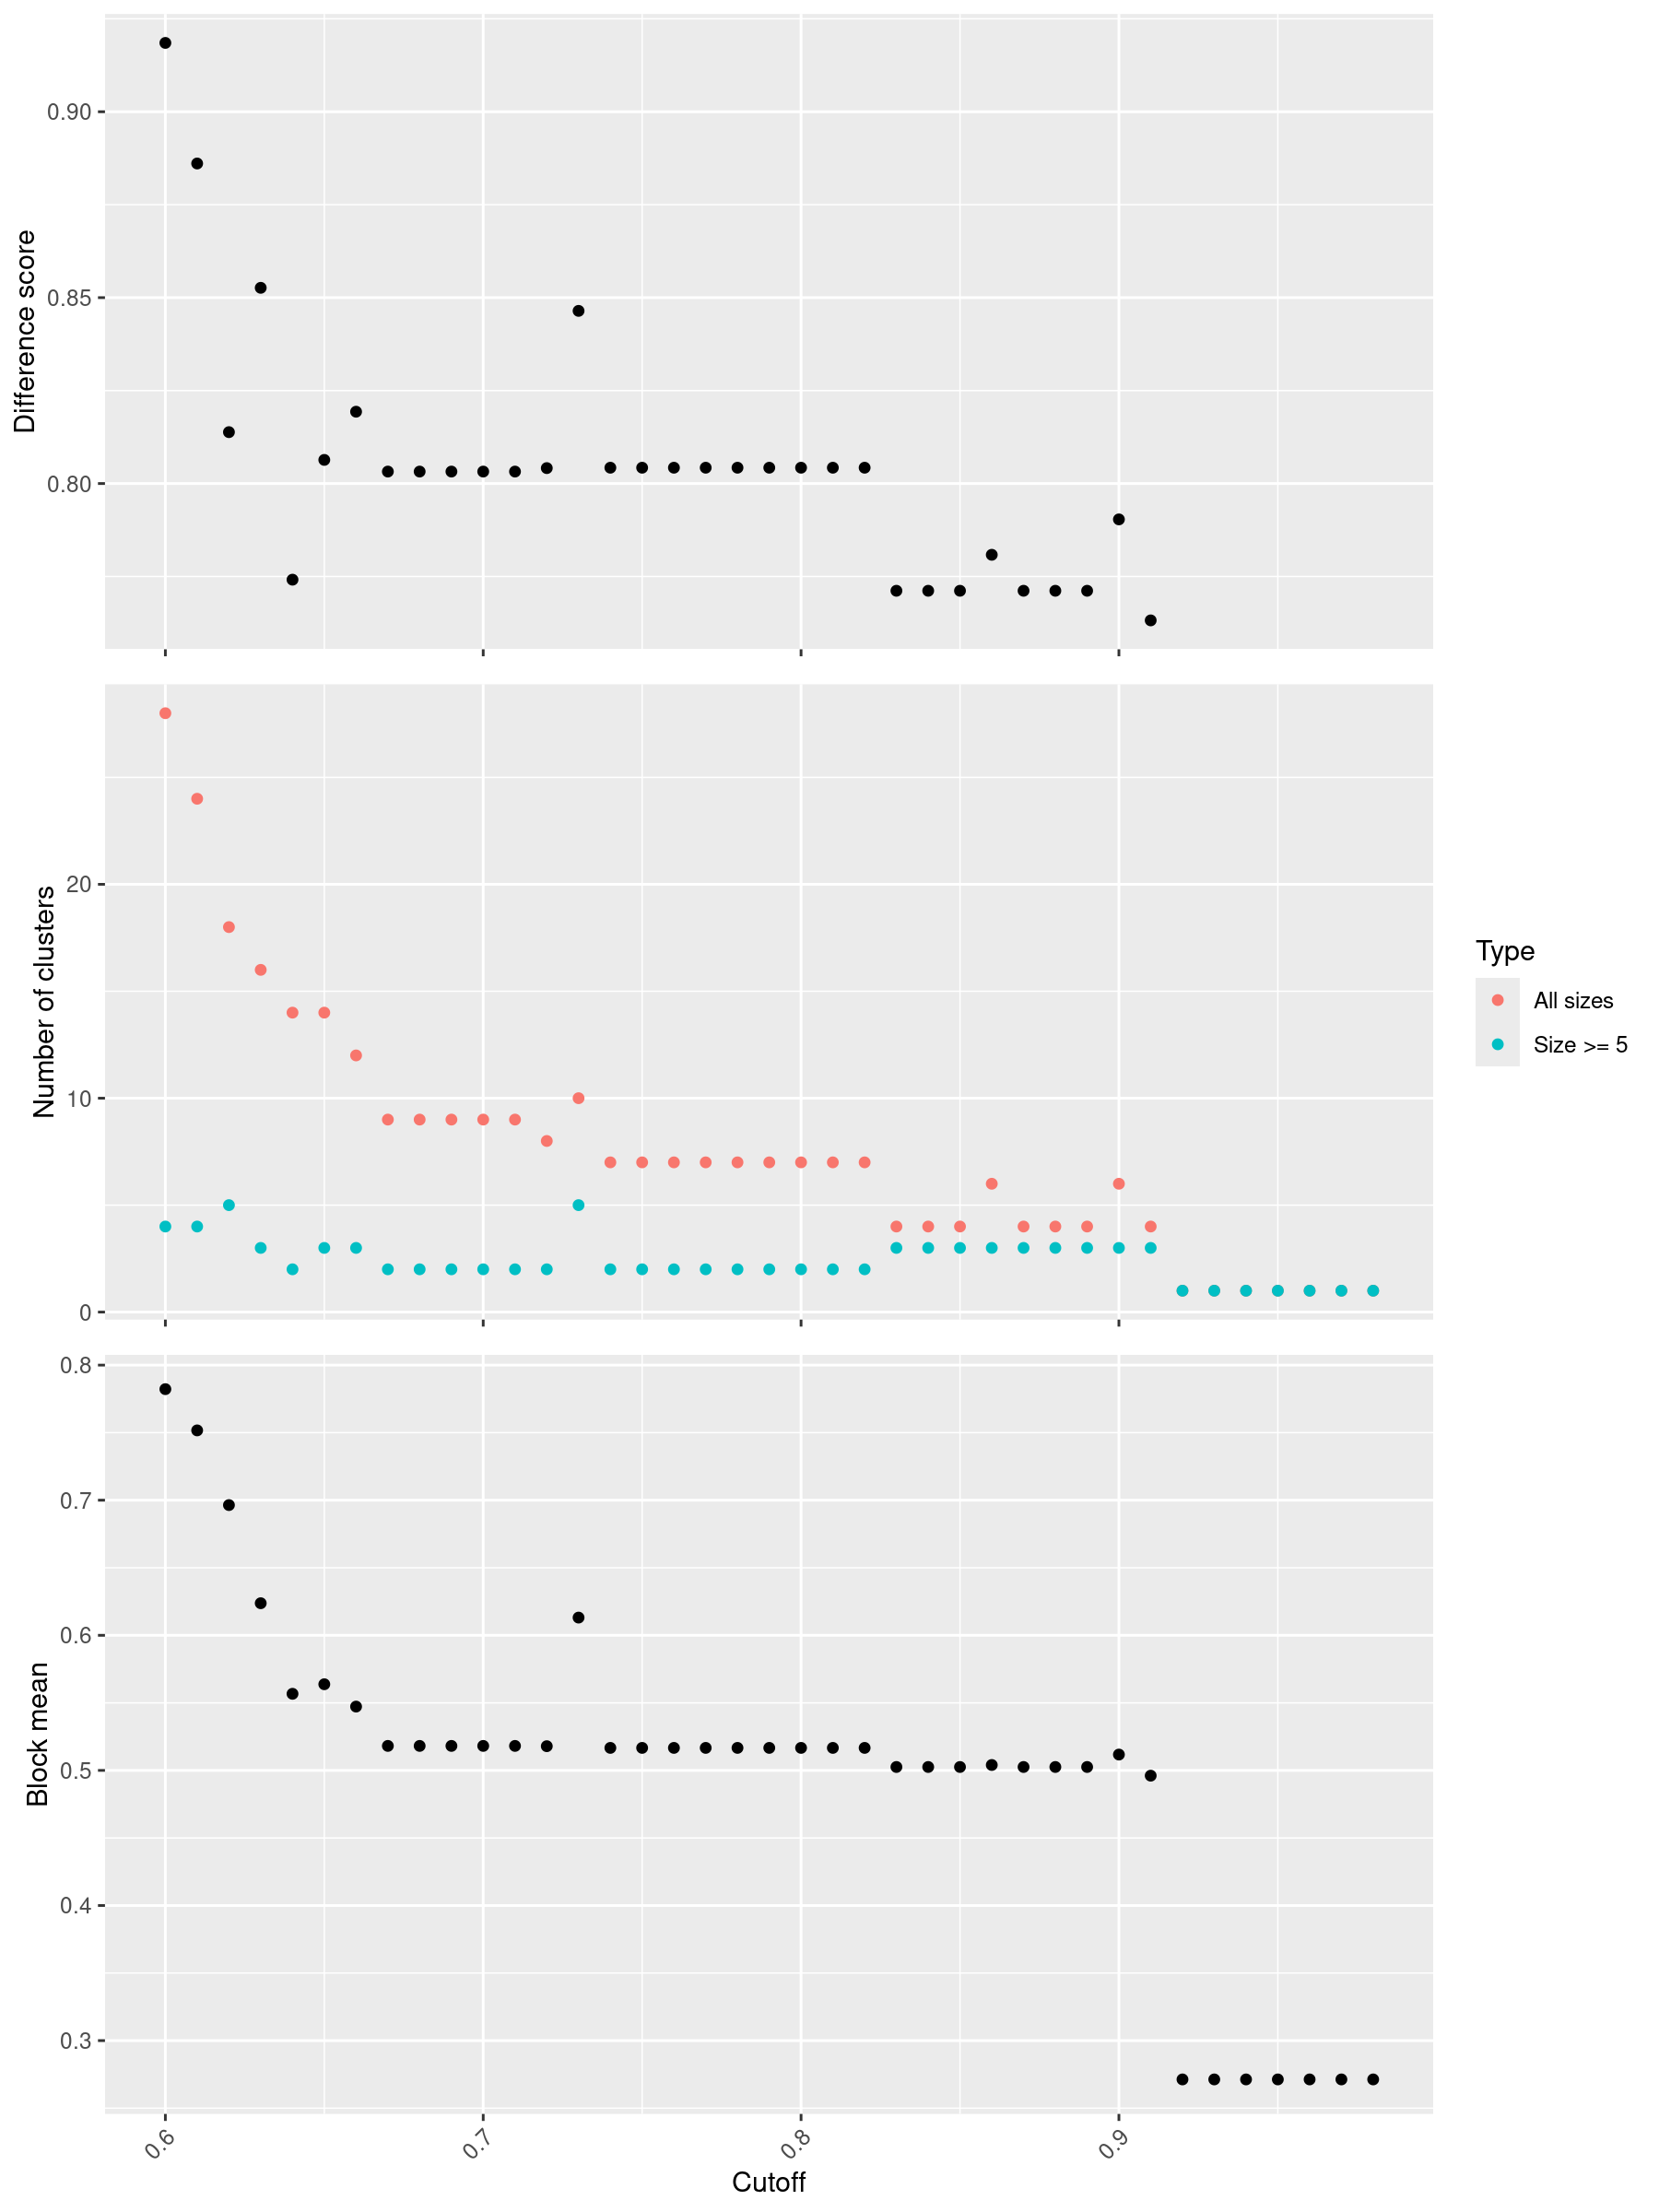

In [11]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_bp_select_cutoff.png"))

In [12]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_bp_simplifyGO.png",
  width = 2500,
  height = 1700,
  res = 300
)
df_bp <- simplifyGO(
  mat_bp,
  # 0.8 sits just before the block-mean collapse on select_cutoff()
  control = list(cutoff = 0.8), # add cutoff parameter
  verbose = FALSE,
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_bp$cluster))


 1  2  3  4  5  6  7 
23 25  1  2  4  2  1 


Perform keywords enrichment for 7 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


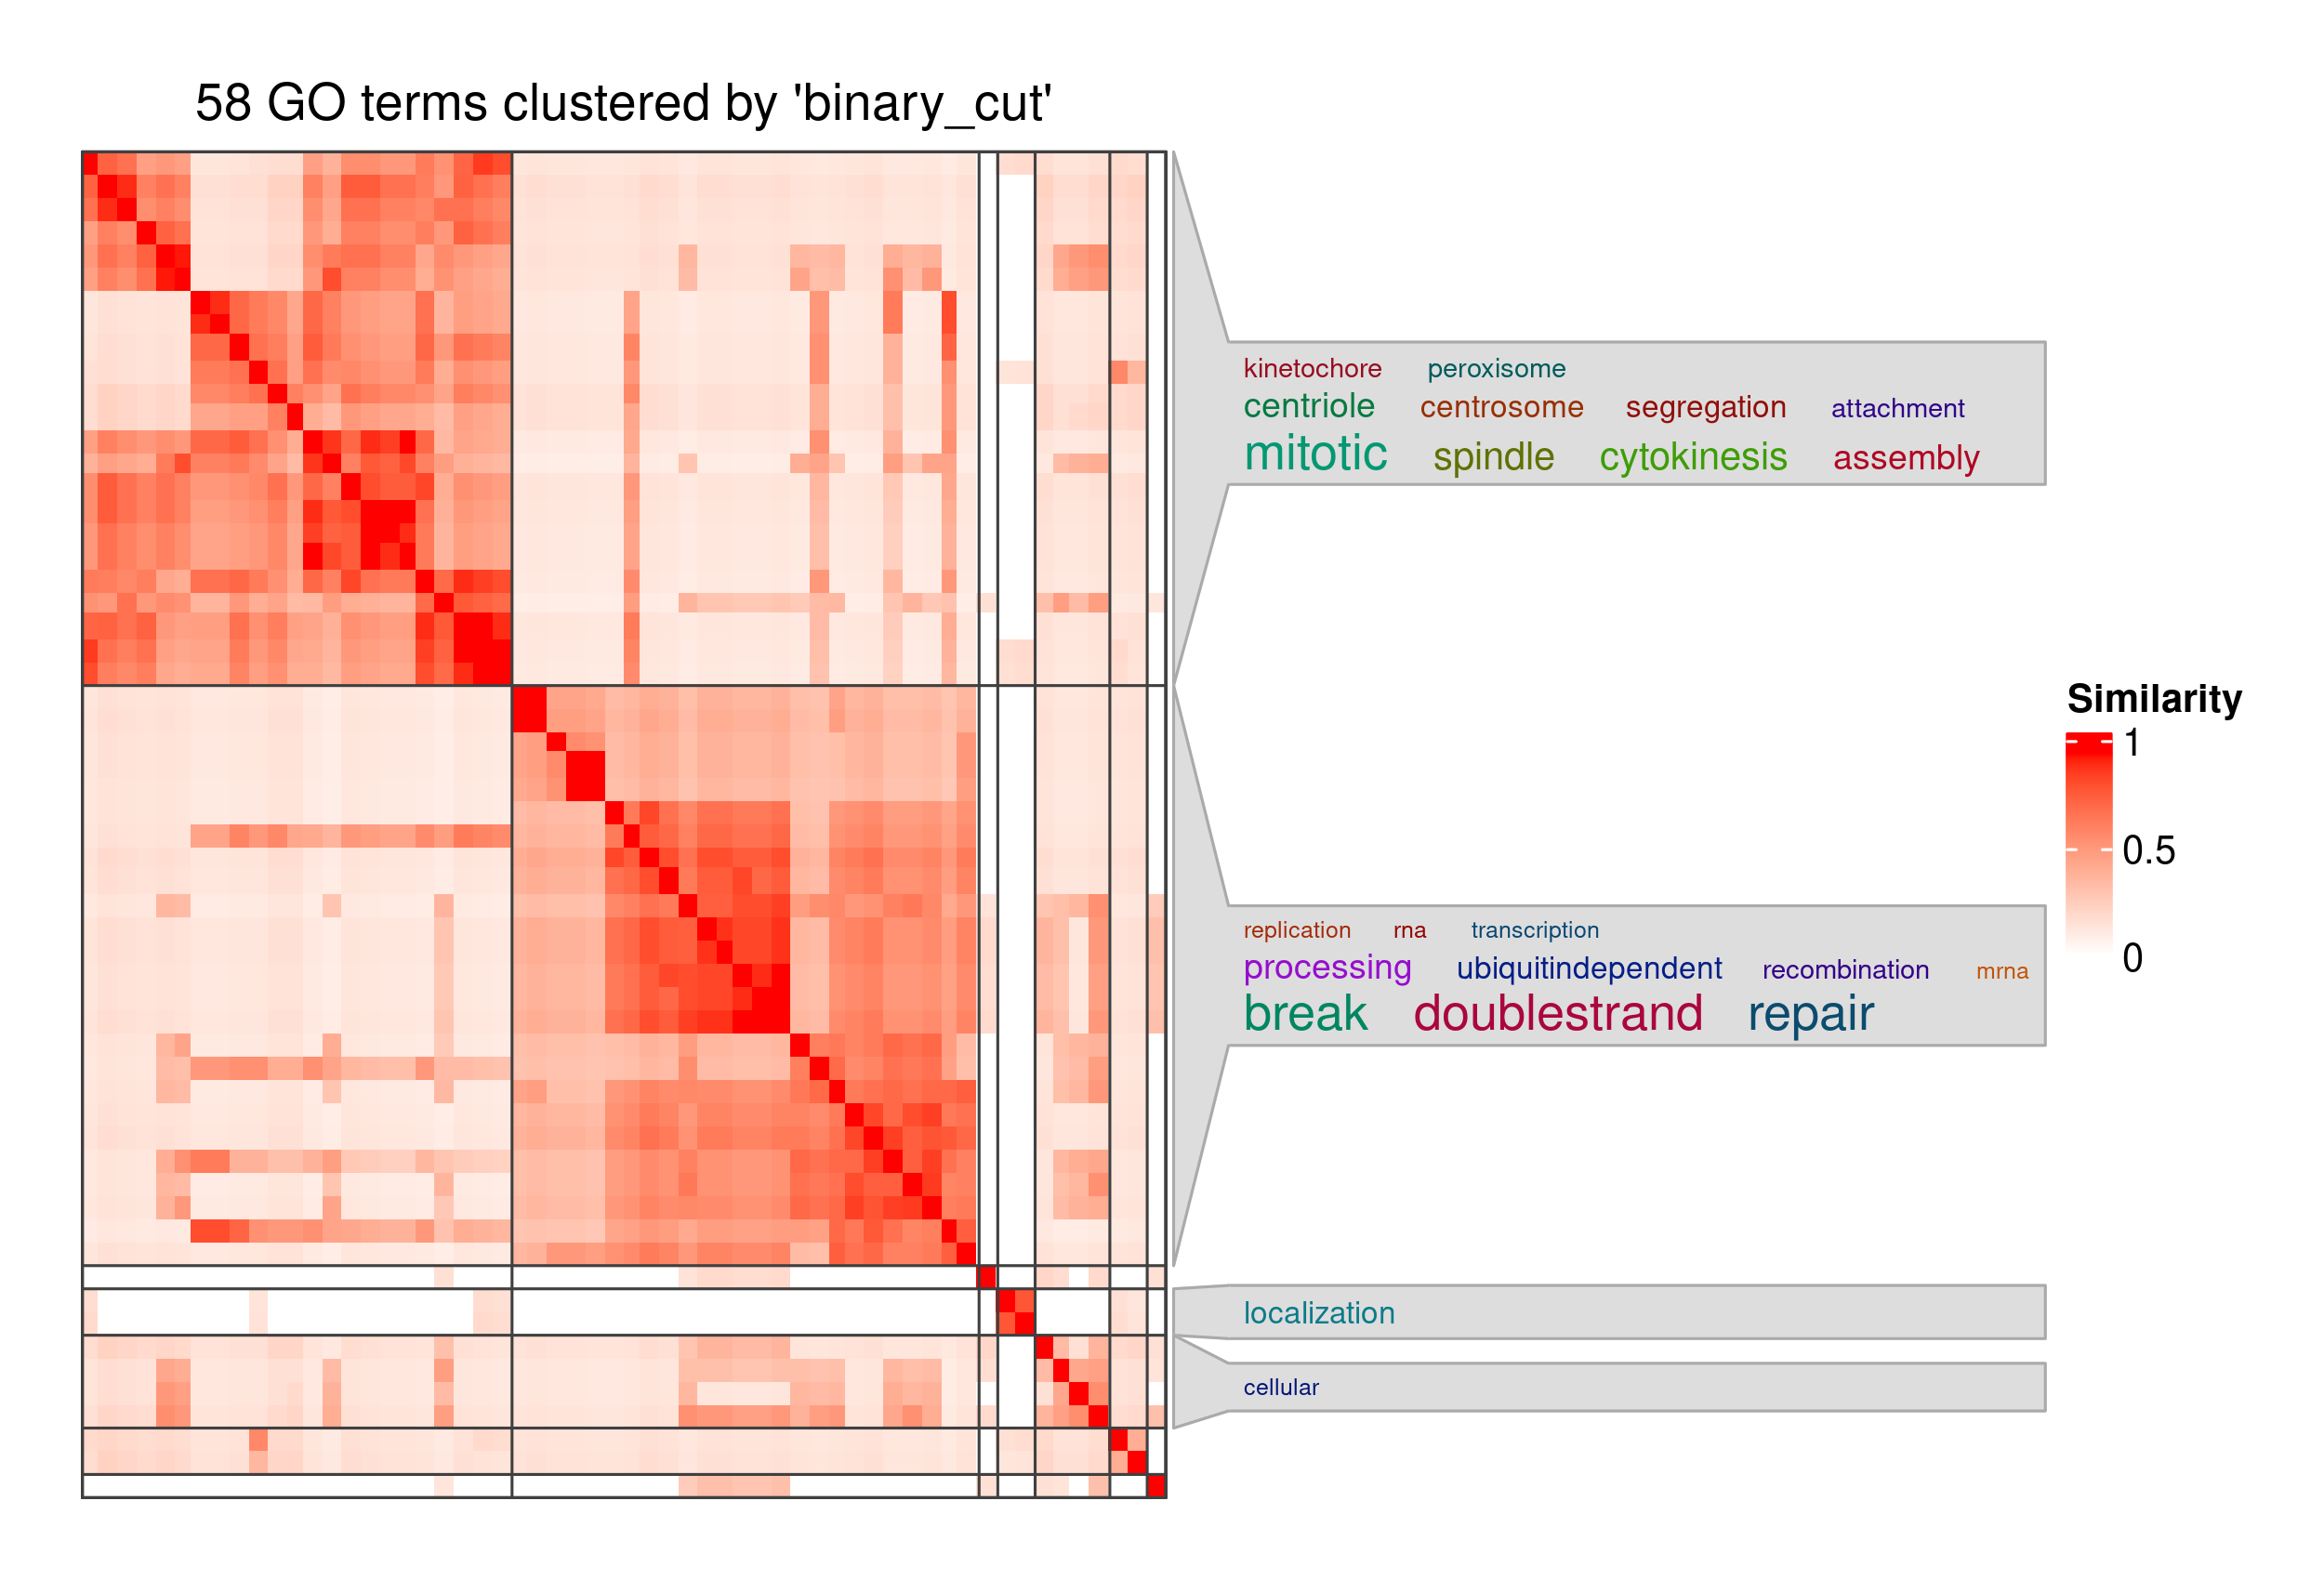

In [13]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_bp_simplifyGO.png"))

&nbsp;

&nbsp;

&nbsp;

## Molecular Function (MF)

In [14]:
%%R -i go_ids_mf
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_mf <- as.character(go_ids_mf)

dag_mf <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "molecular_function")]
)
print(dag_mf)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_mf <- term_sim(dag_mf, go_ids_mf, method = "Sim_WP_1994")
print(dim(mat_mf))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  10041 terms / 12472 relations
  Root: GO:0003674 
  Terms: GO:0000006, GO:0000007, GO:0000009, GO:0000010, ...
  Max depth: 12 
  Avg number of parents: 1.24
  Avg number of children: 1.31
  Aspect ratio: 384.8:1 (based on the longest distance from root)
                531.12:1 (based on the shortest distance from root)
  Relations: is_a, negatively_regulates, part_of, positively_regulates,
             regulates
  Relation types may have hierarchical relations.

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 38 38


In [15]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_mf_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_mf)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


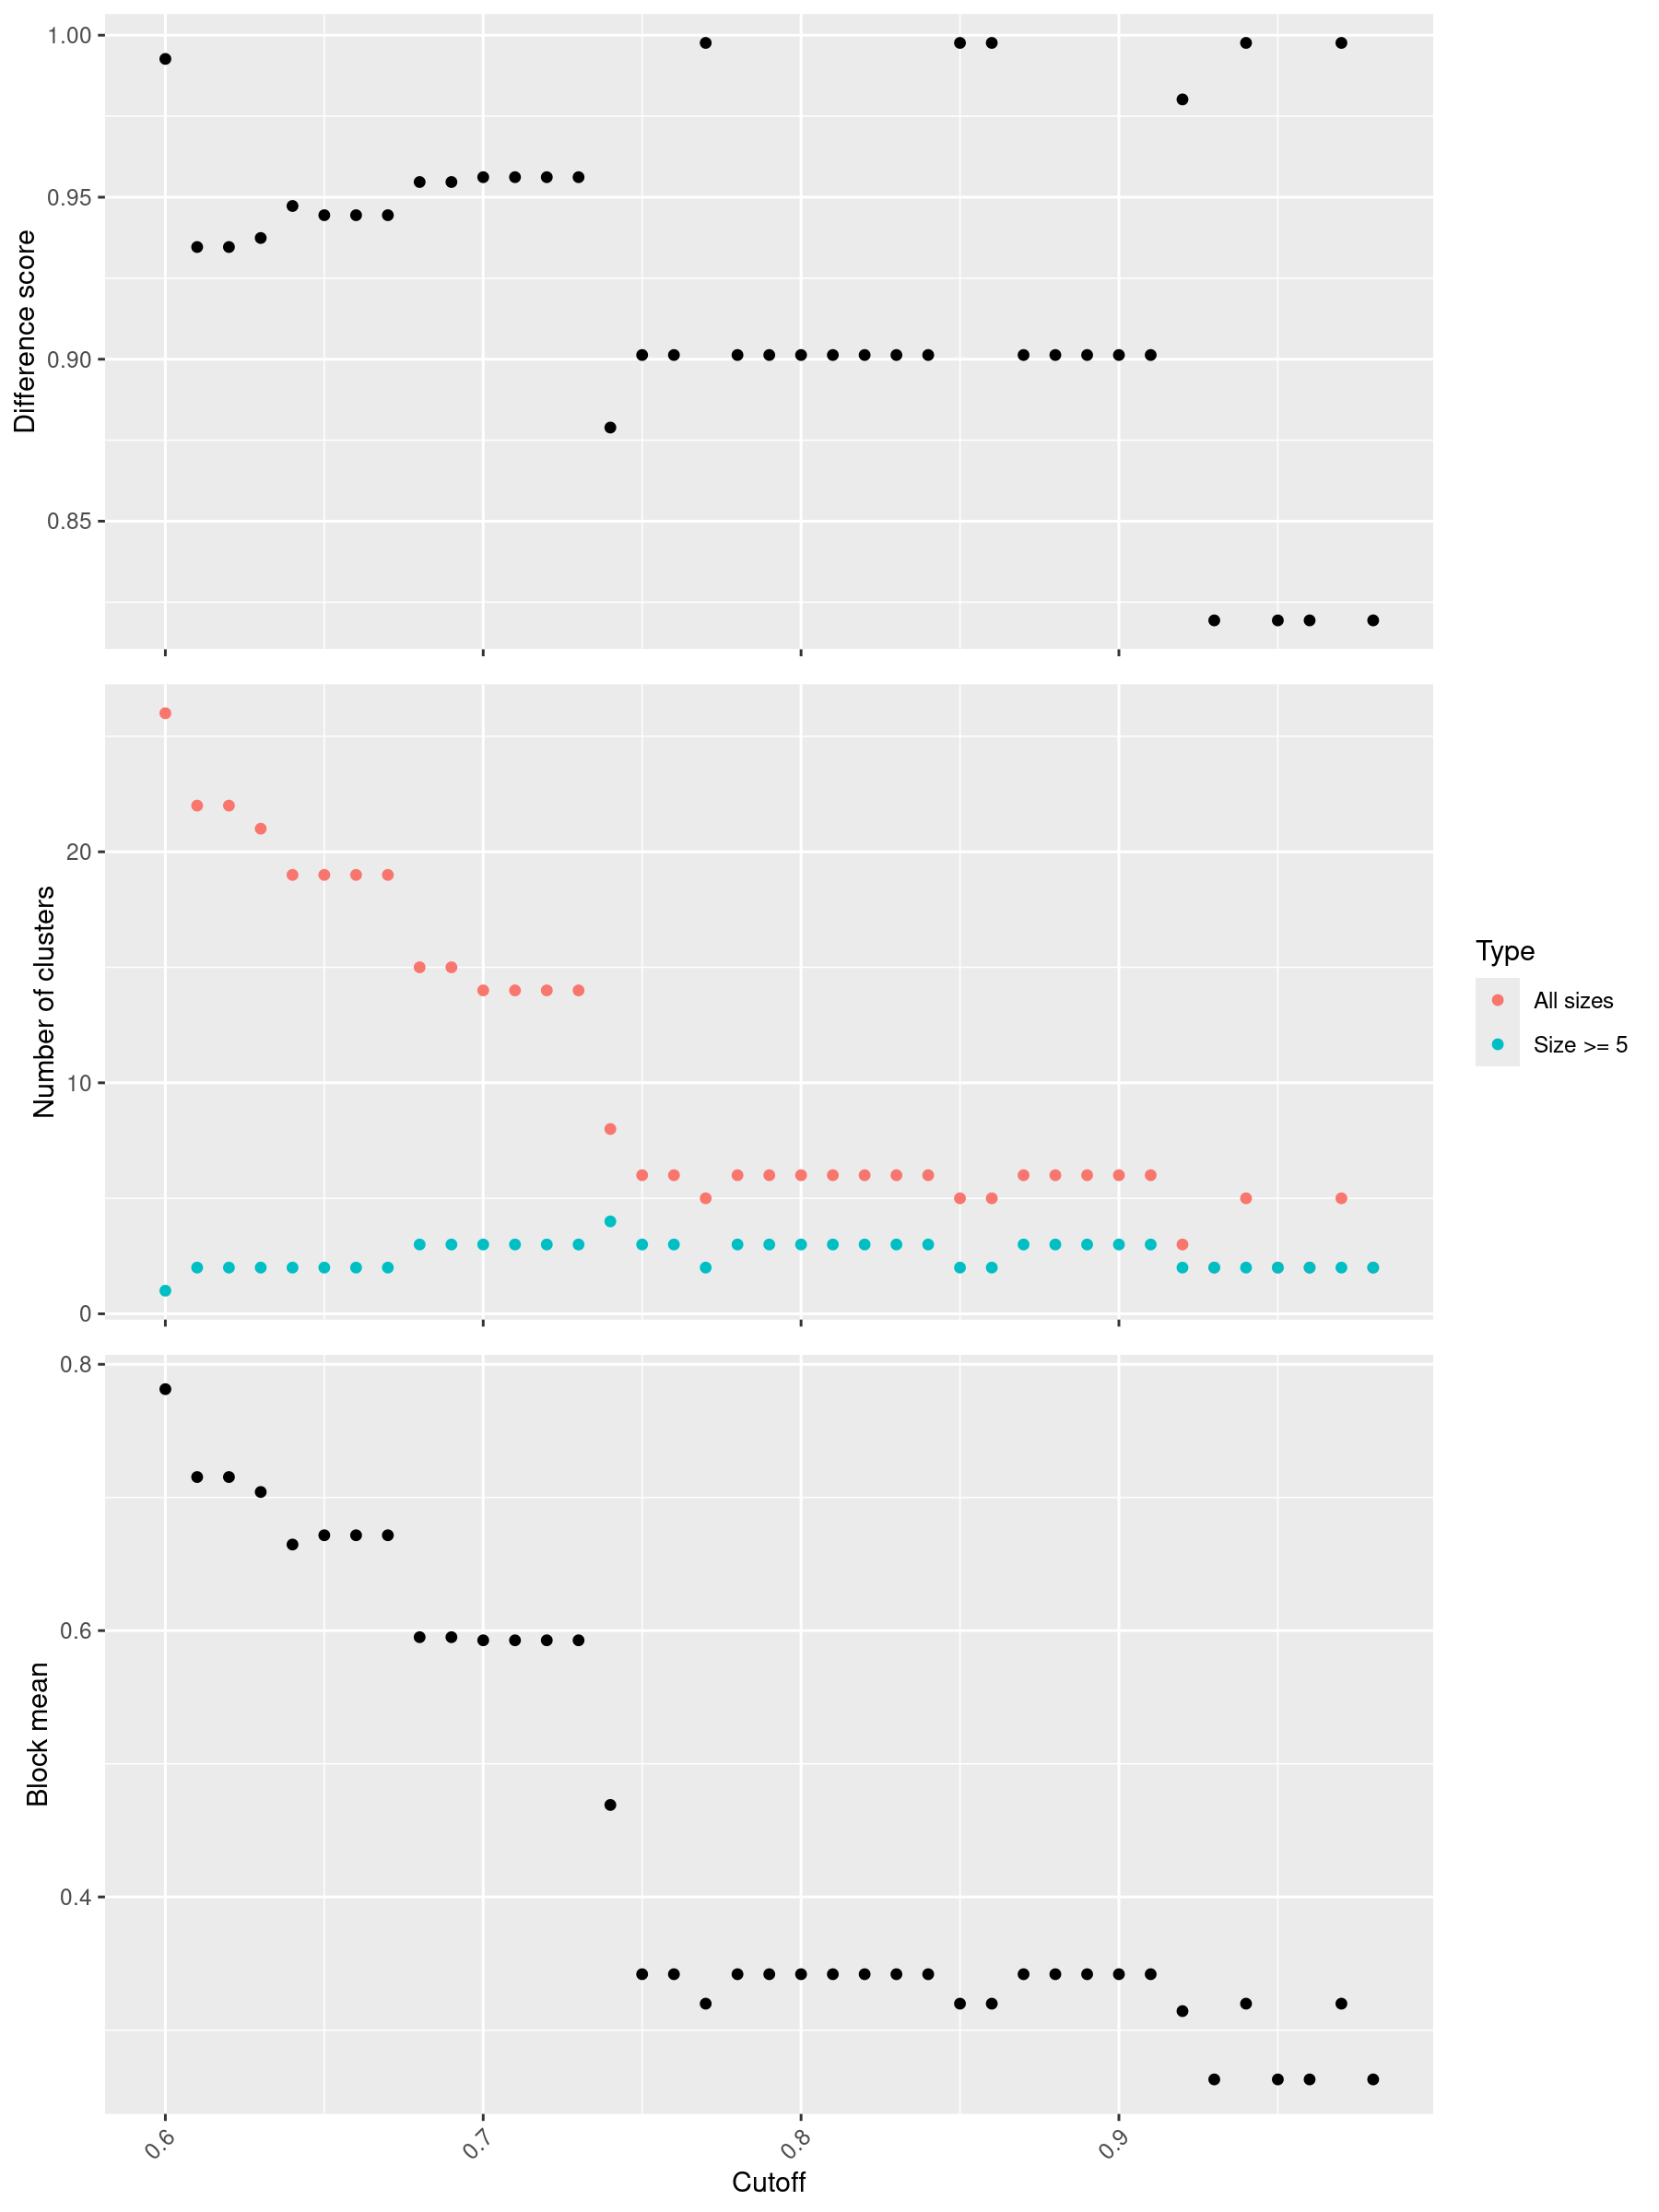

In [16]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_mf_select_cutoff.png"))

In [17]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_mf_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_mf <- simplifyGO(
  mat_mf,
  verbose = FALSE,
  control = list(cutoff = 0.8), # add cutoff parameter
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_mf$cluster))


 1  2  3  4  5 
14  1 20  2  1 


Perform keywords enrichment for 5 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


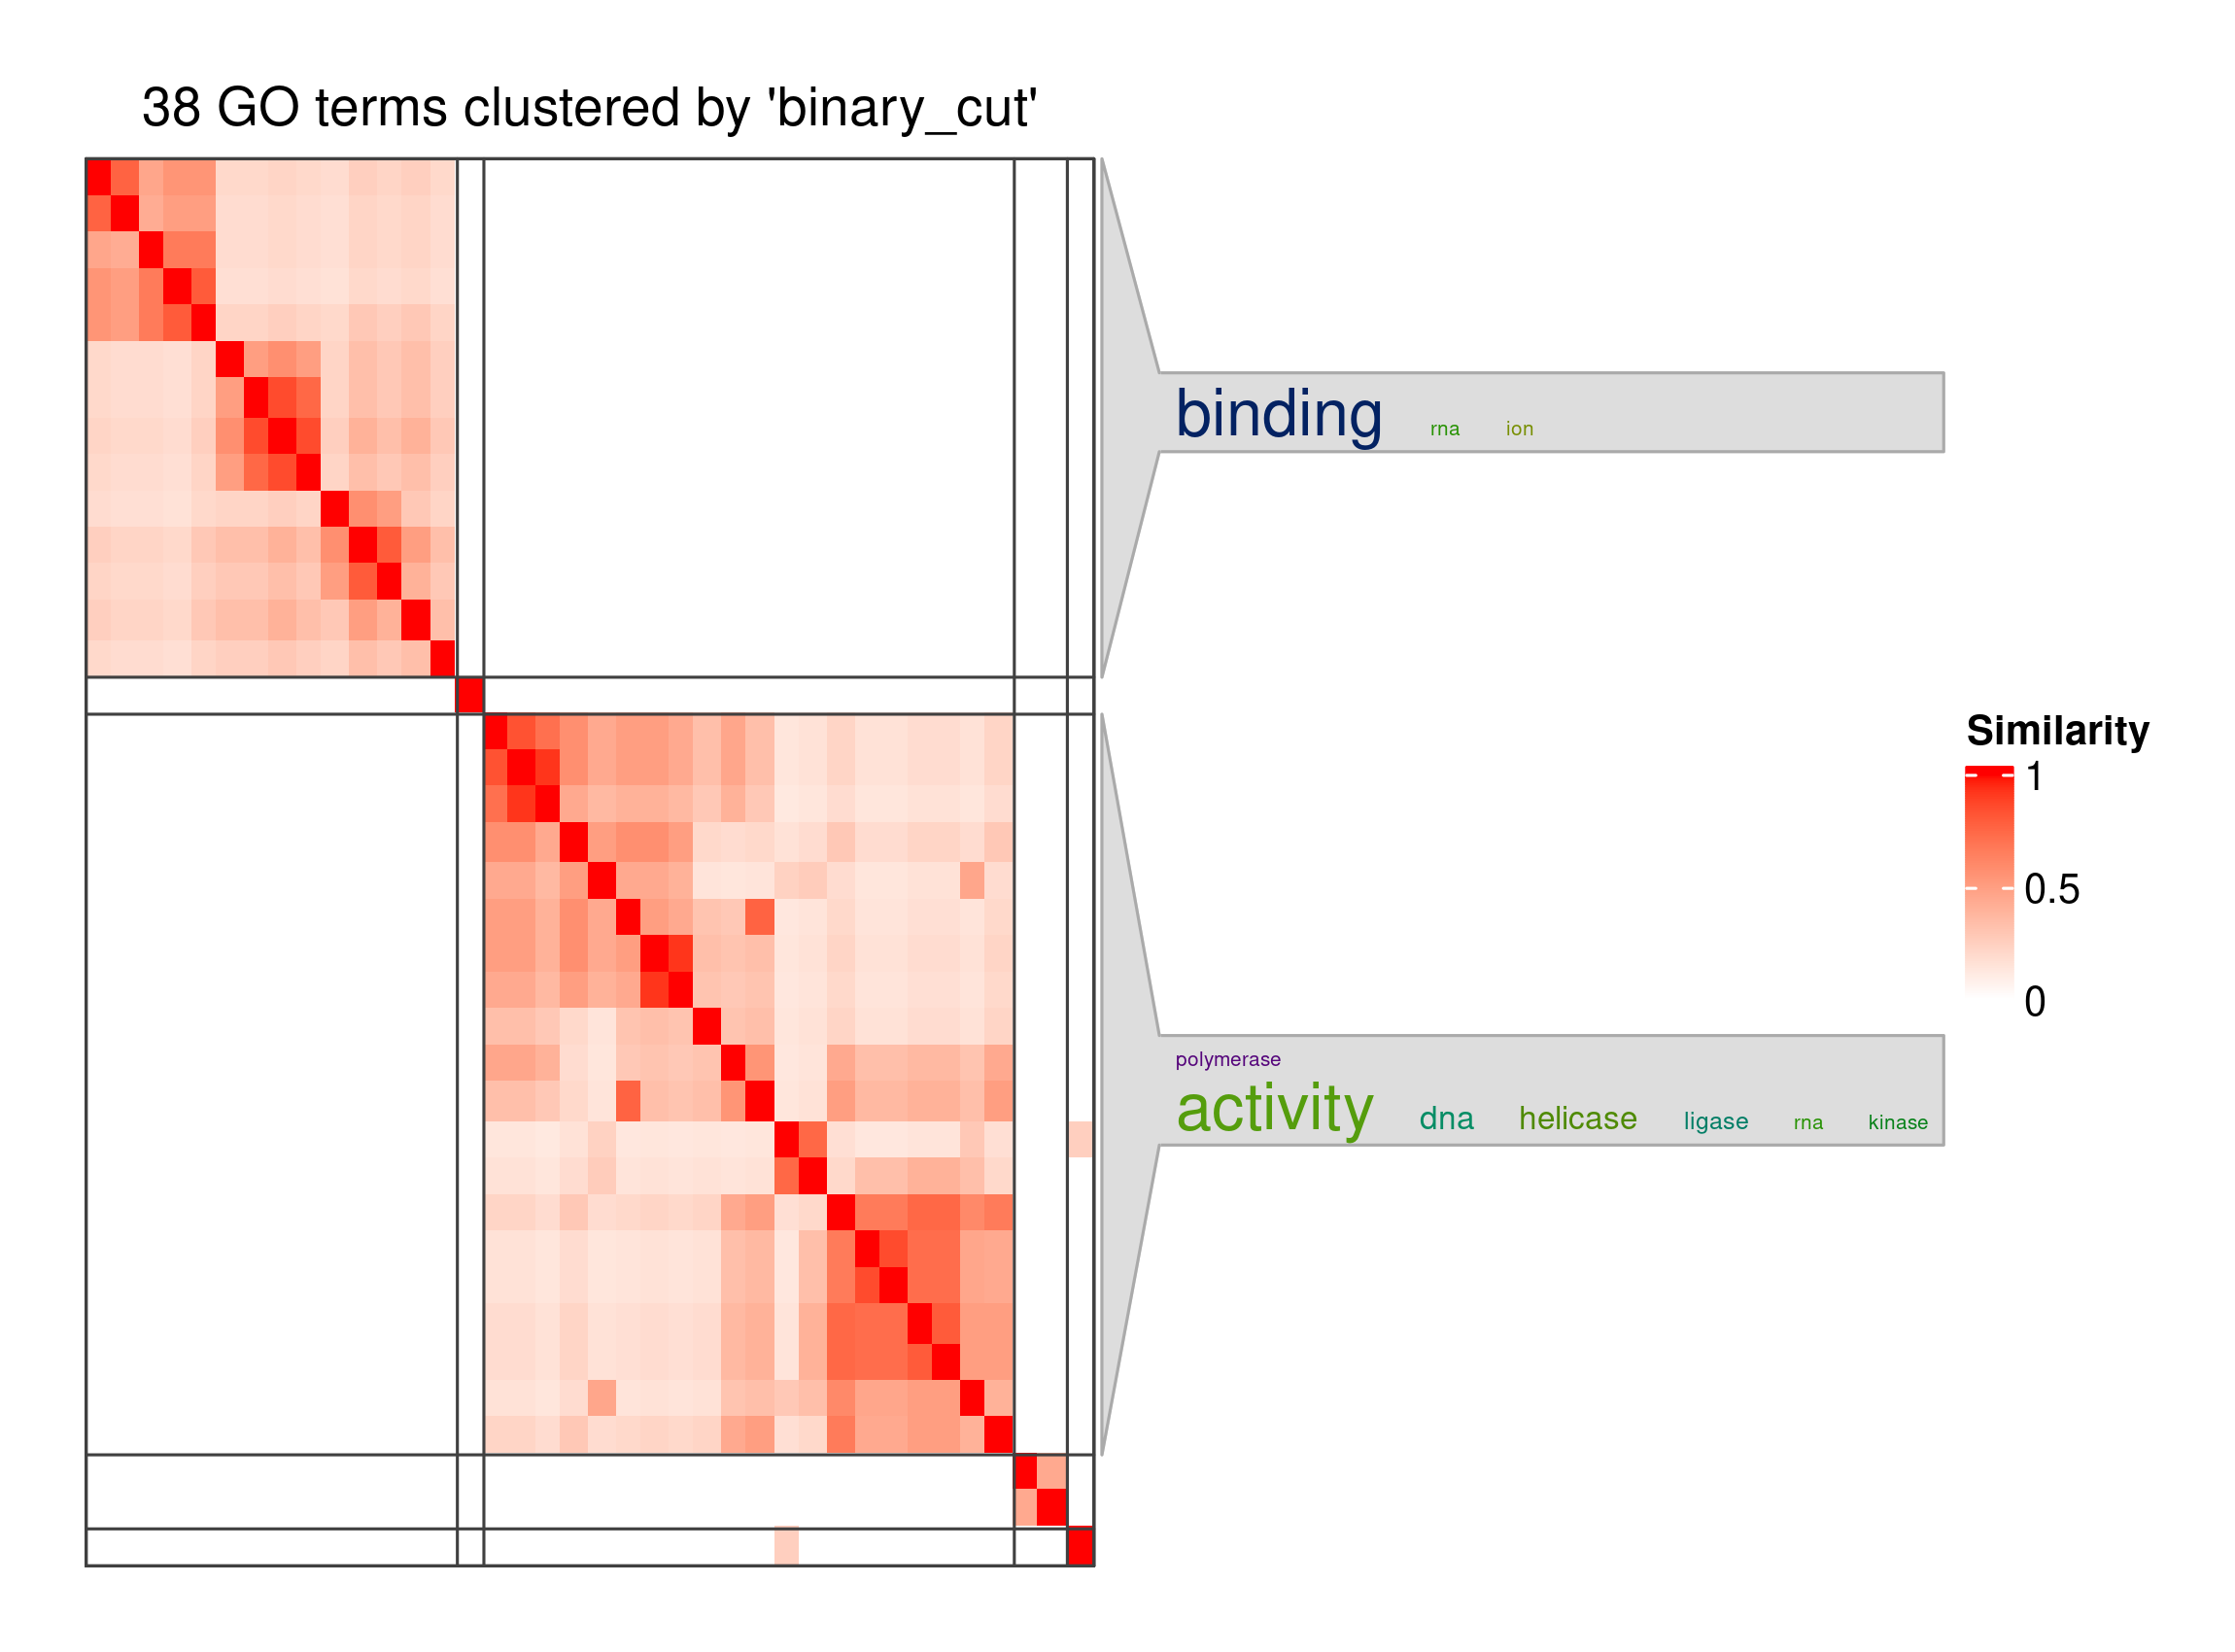

In [18]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_mf_simplifyGO.png"))

&nbsp;

&nbsp;

## Cellular Component (CC)

In [19]:
%%R -i go_ids_cc
# https://jokergoo.github.io/simona/articles/v02_GO.html
go_ids_cc <- as.character(go_ids_cc)

dag_cc <- dag_filter(
  dag_go,
  terms = mcols(dag_go)$id[which(mcols(dag_go)$namespace == "cellular_component")]
)
print(dag_cc)

# Do not print the matrix. The enriched term set is too large for the notebook.
mat_cc <- term_sim(dag_cc, go_ids_cc, method = "Sim_WP_1994")
print(dim(mat_cc))

An ontology_DAG object:
  Source: go, releases/2026-07-26 
  4077 terms / 6496 relations
  Root: GO:0005575 
  Terms: GO:0000015, GO:0000109, GO:0000110, GO:0000111, ...
  Max depth: 14 
  Avg number of parents: 1.59
  Avg number of children: 1.65
  Aspect ratio: 57.55:1 (based on the longest distance from root)
                172.71:1 (based on the shortest distance from root)
  Relations: is_a, part_of

With the following columns in the metadata data frame:
  id, short_id, name, namespace, definition
[1] 71 71


In [20]:
%%R
# cowplot is required by select_cutoff()
if (!requireNamespace("cowplot", quietly = TRUE)) {
  install.packages("cowplot", repos = "https://cloud.r-project.org")
}

# Default cutoff grid is 0.6 to 0.98 by 0.01
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_cc_select_cutoff.png",
  width = 1800,
  height = 2400,
  res = 200
)
select_cutoff(mat_cc)
invisible(dev.off())

1/39, cutoff = 0.6...
2/39, cutoff = 0.61...
3/39, cutoff = 0.62...
4/39, cutoff = 0.63...
5/39, cutoff = 0.64...
6/39, cutoff = 0.65...
7/39, cutoff = 0.66...
8/39, cutoff = 0.67...
9/39, cutoff = 0.68...
10/39, cutoff = 0.69...
11/39, cutoff = 0.7...
12/39, cutoff = 0.71...
13/39, cutoff = 0.72...
14/39, cutoff = 0.73...
15/39, cutoff = 0.74...
16/39, cutoff = 0.75...
17/39, cutoff = 0.76...
18/39, cutoff = 0.77...
19/39, cutoff = 0.78...
20/39, cutoff = 0.79...
21/39, cutoff = 0.8...
22/39, cutoff = 0.81...
23/39, cutoff = 0.82...
24/39, cutoff = 0.83...
25/39, cutoff = 0.84...
26/39, cutoff = 0.85...
27/39, cutoff = 0.86...
28/39, cutoff = 0.87...
29/39, cutoff = 0.88...
30/39, cutoff = 0.89...
31/39, cutoff = 0.9...
32/39, cutoff = 0.91...
33/39, cutoff = 0.92...
34/39, cutoff = 0.93...
35/39, cutoff = 0.94...
36/39, cutoff = 0.95...
37/39, cutoff = 0.96...
38/39, cutoff = 0.97...
39/39, cutoff = 0.98...


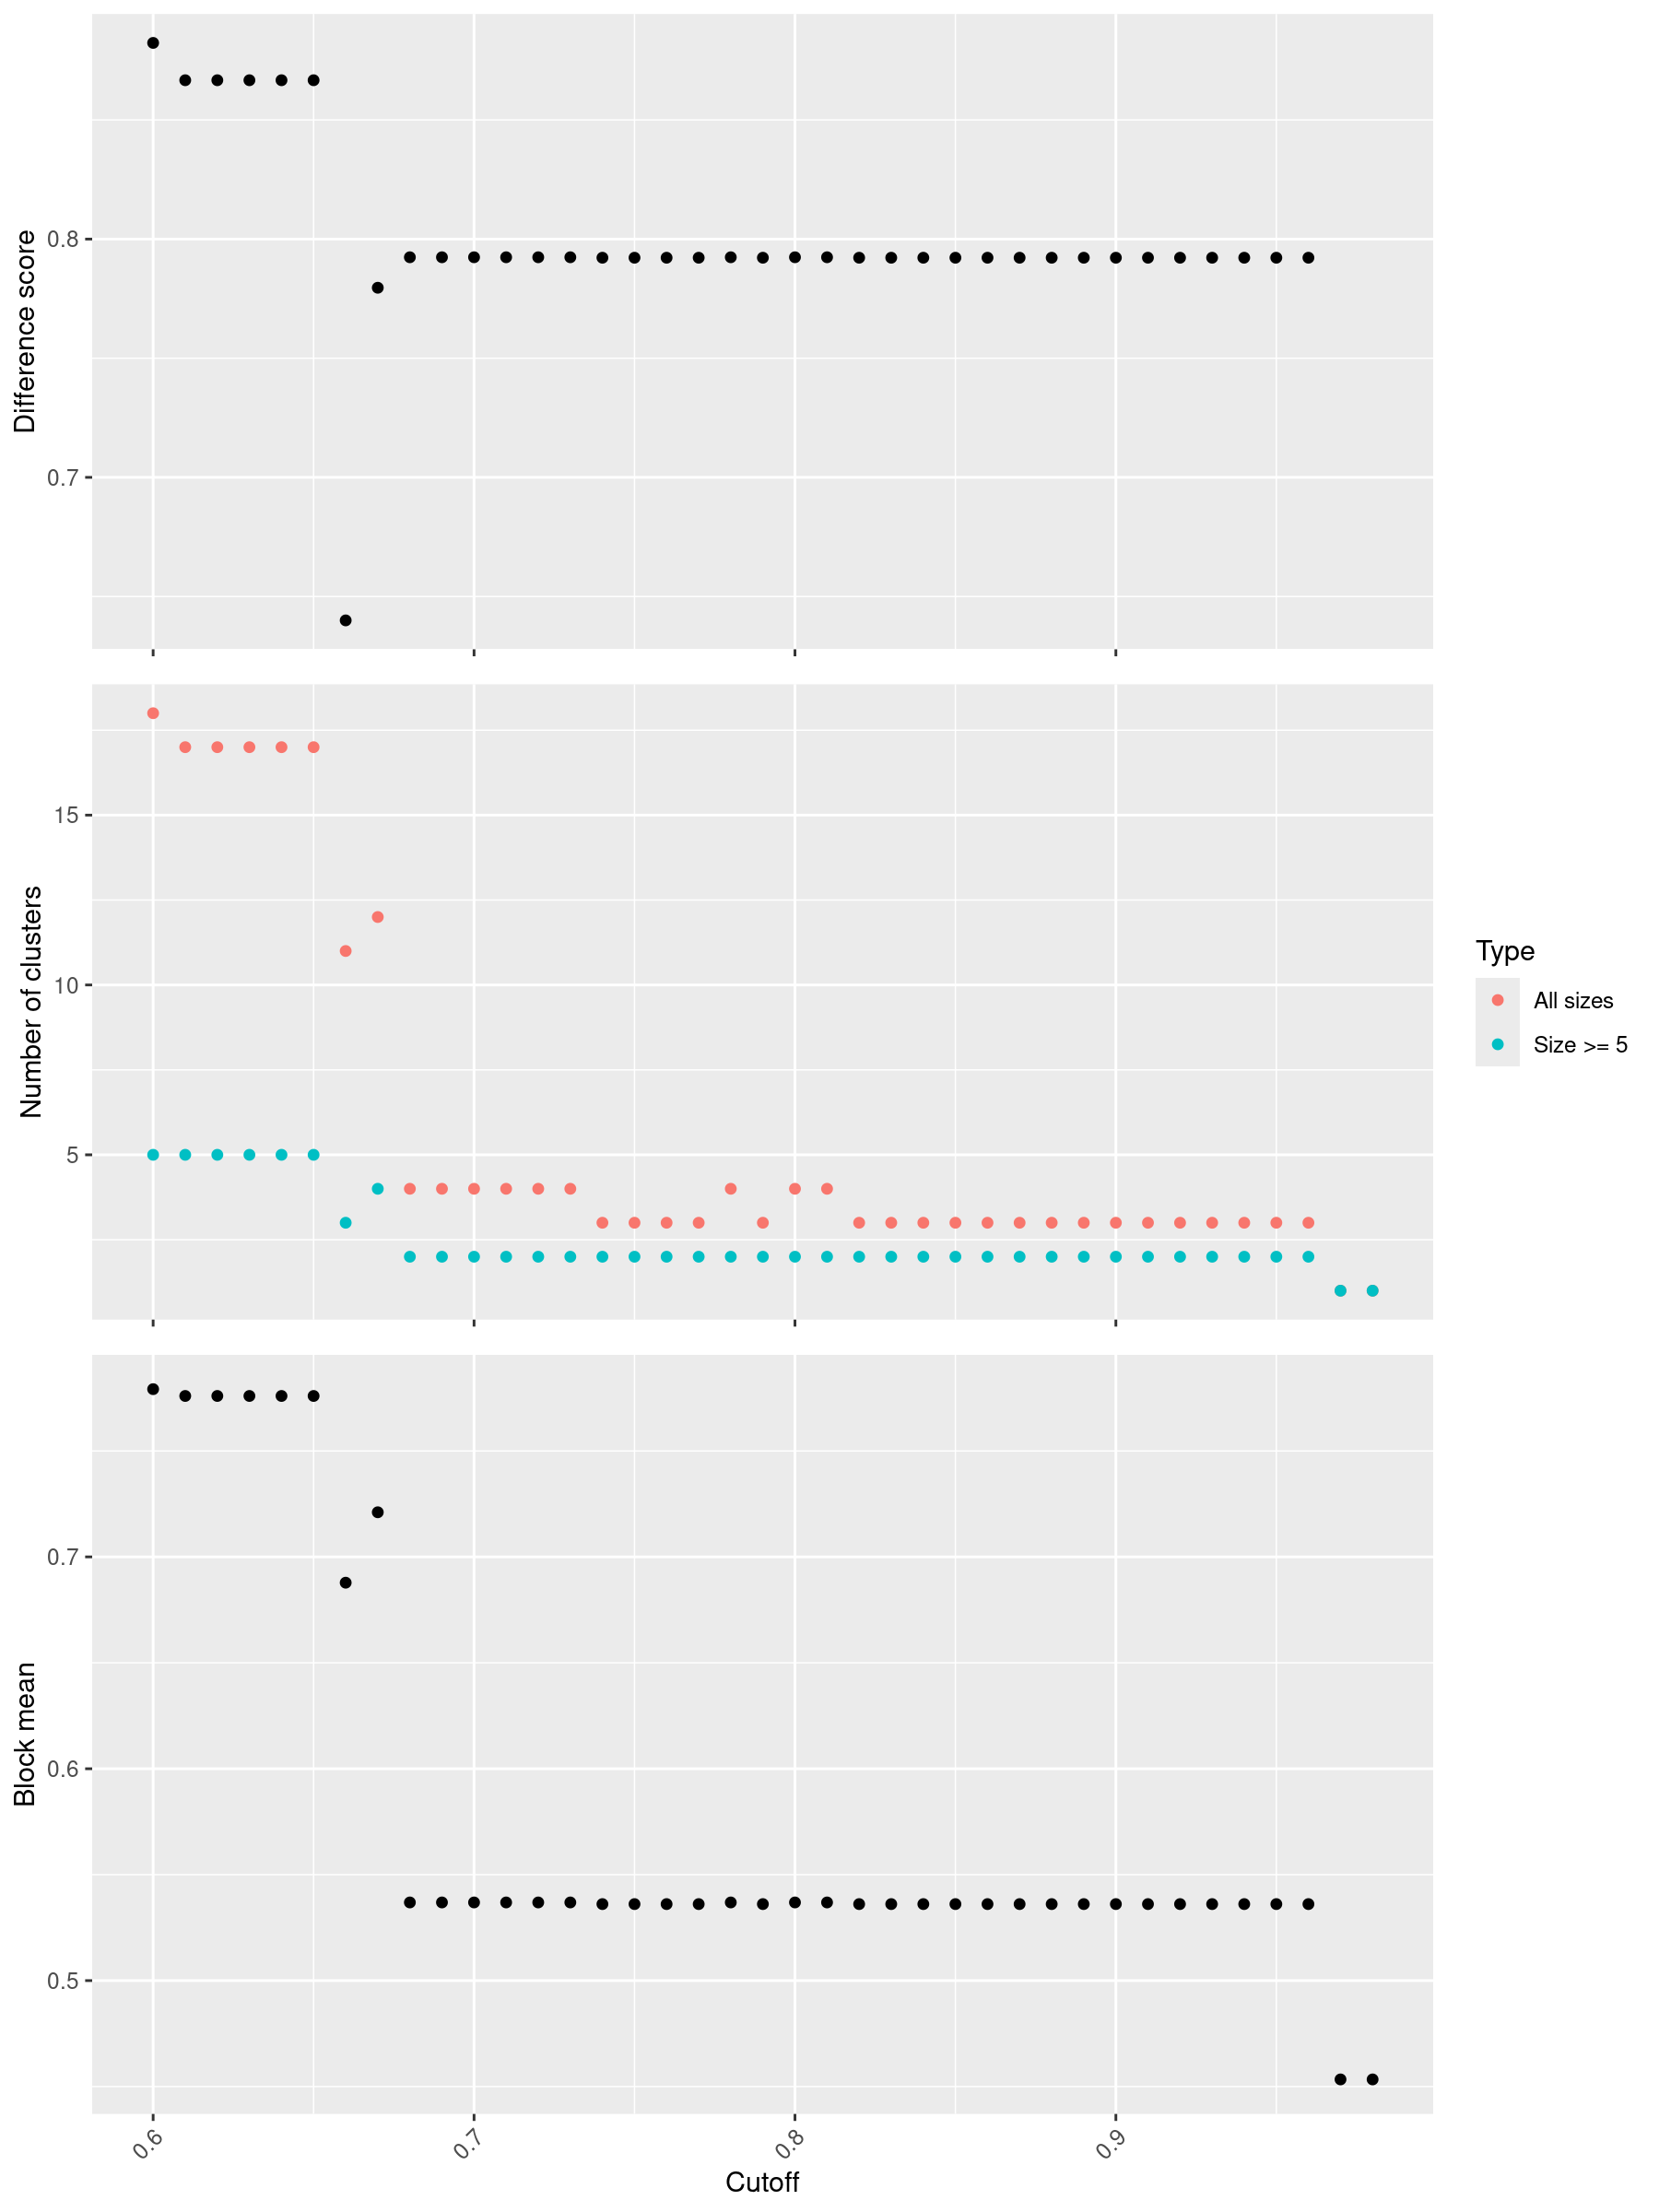

In [21]:
# Uncomment after running select_cutoff() above.
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_cc_select_cutoff.png"))

In [22]:
%%R
png(
  "../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_cc_simplifyGO.png",
  width = 2300,
  height = 1700,
  res = 300
)
df_cc <- simplifyGO(
  mat_cc,
  verbose = FALSE,
  control = list(cutoff = 0.8), # add cutoff parameter
  padding = unit(c(7.5, 7.5, 7.5, 7.5), "mm"),
  word_cloud_grob_param = list(
    fontsize = c(15, 25),
    max_width = 70,
    word_space = 4
  )
)
invisible(dev.off())

print(table(df_cc$cluster))


 1  2  3 
 7 63  1 


Perform keywords enrichment for 3 GO lists...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...
keyword enrichment, 3259/3259...


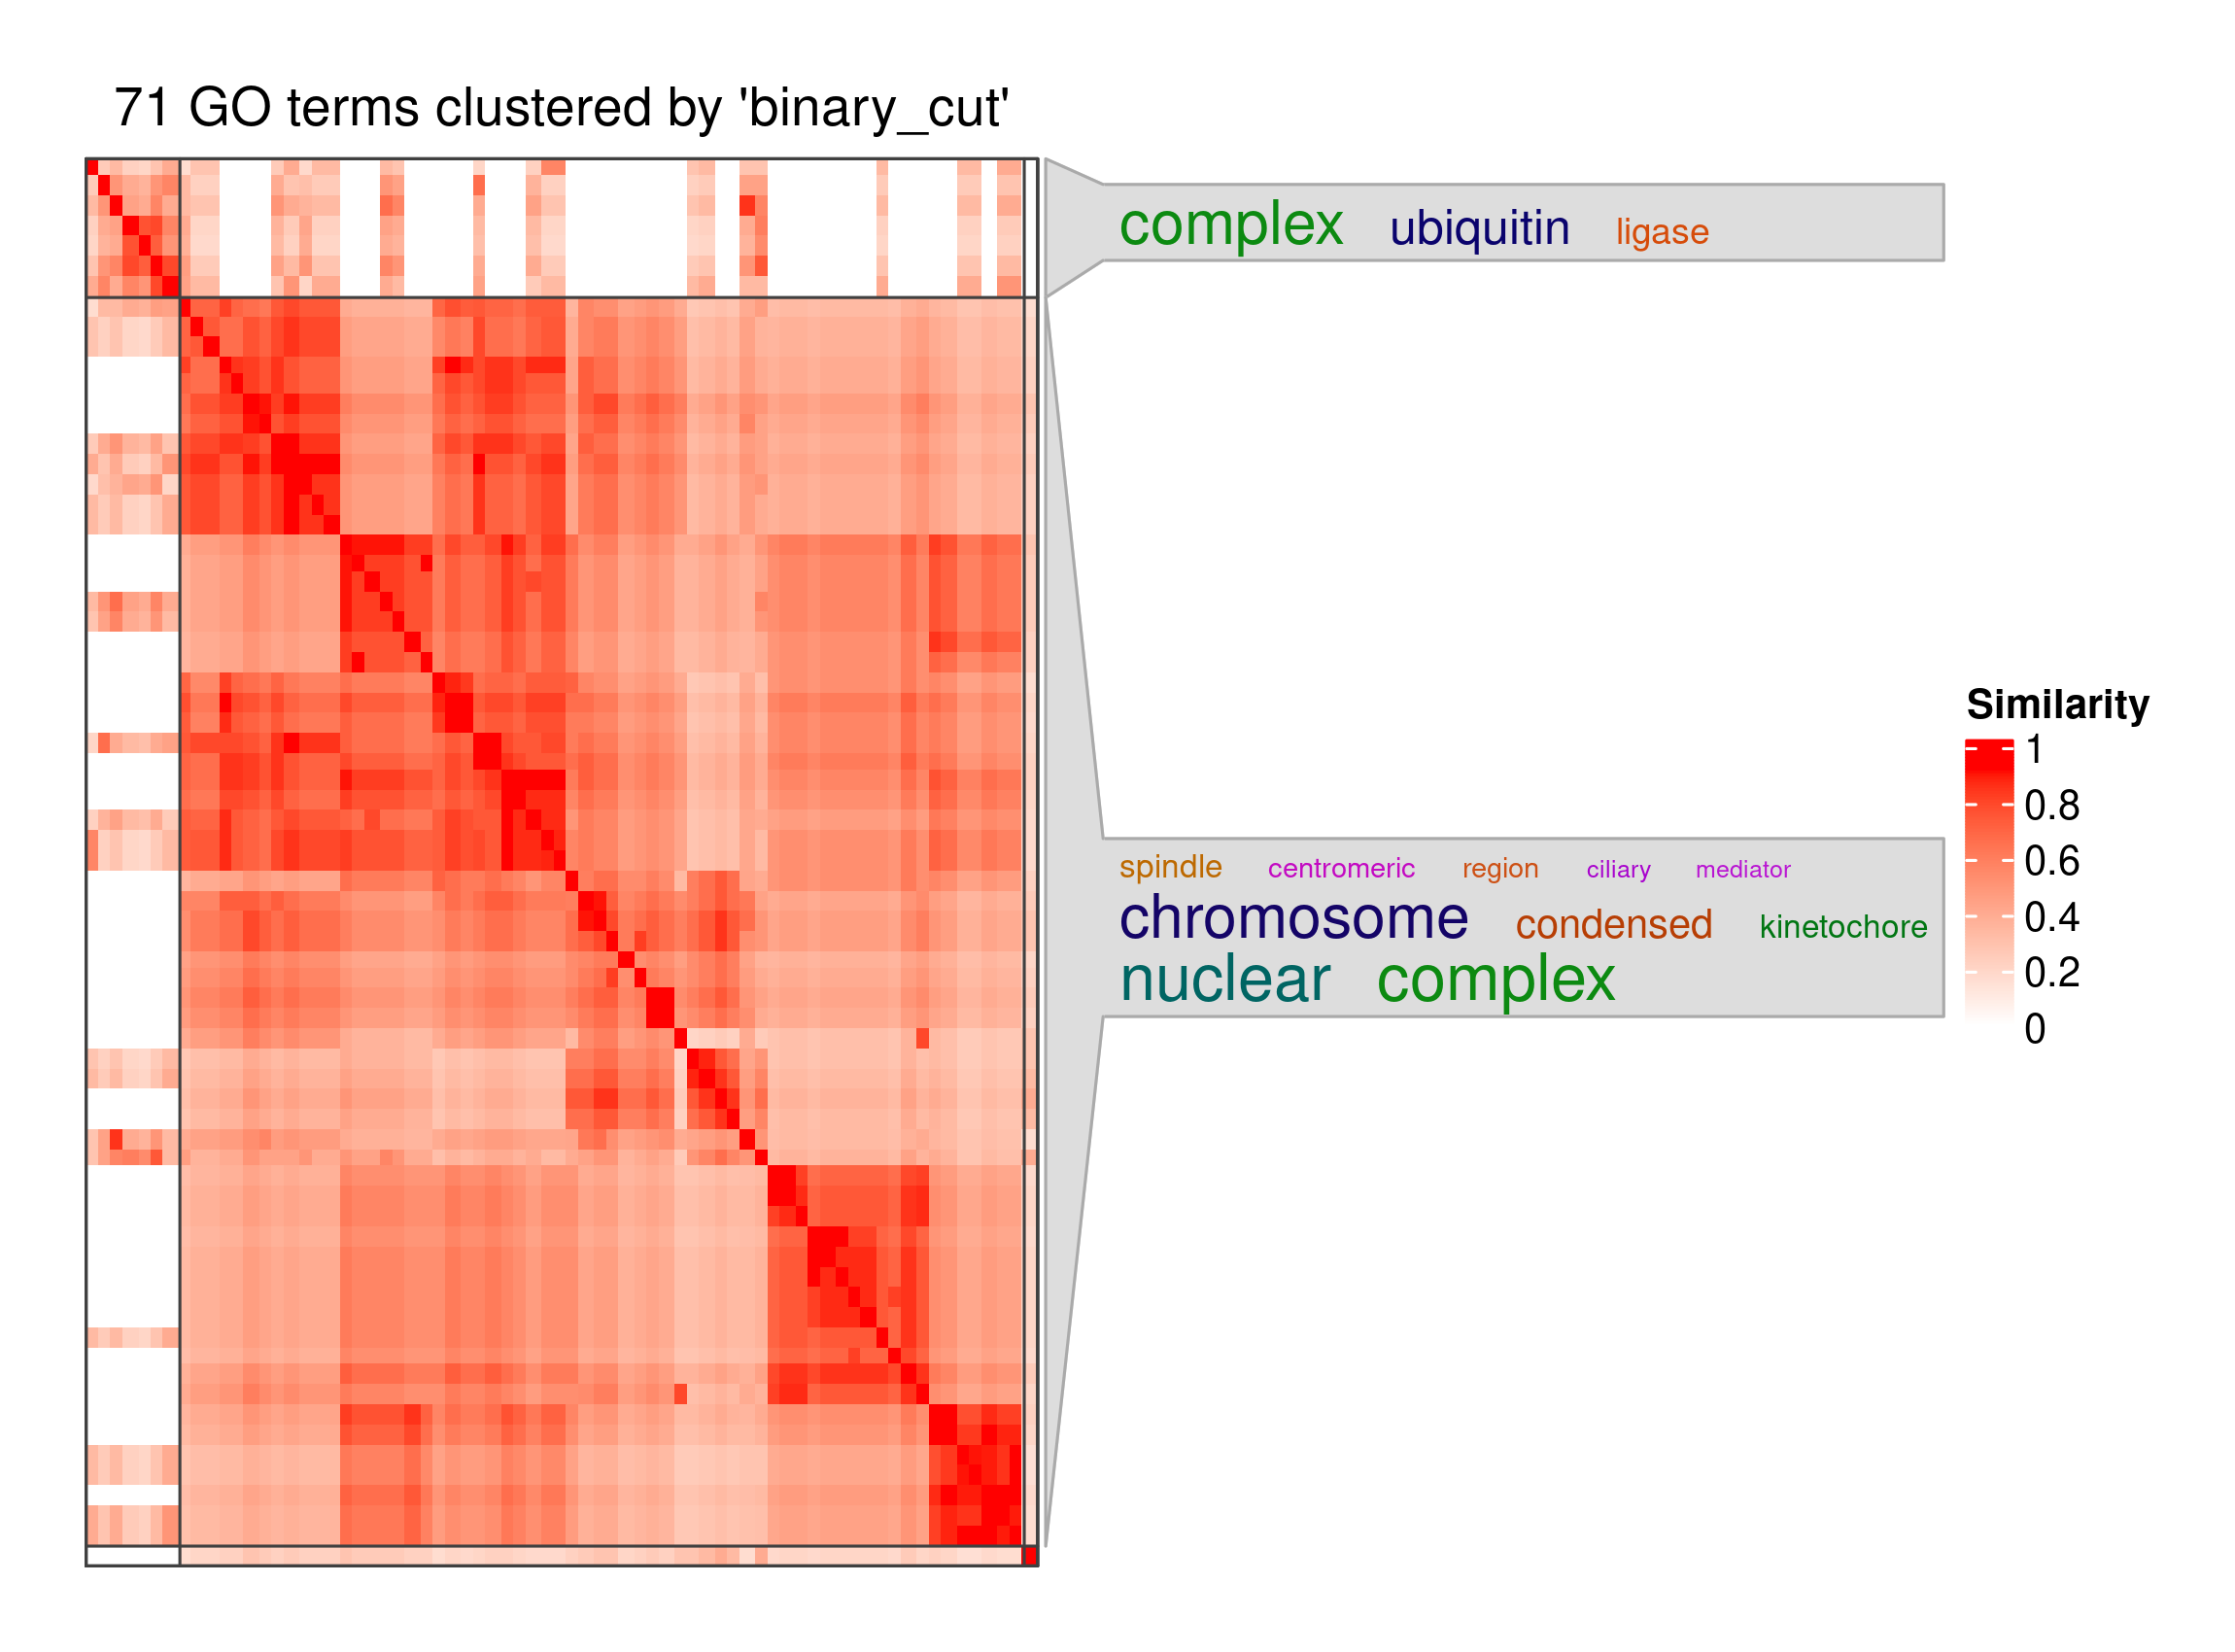

In [23]:
display(Image(filename="../../out/enrichment_analysis/simona/all_pc_transcript_exp/down5p_pc_exp_go_cc_simplifyGO.png"))

&nbsp;

&nbsp;

## Cluster membership

- `simplifyGO()` の戻り値 `df_bp` / `df_mf` / `df_cc` を Polars に渡す
- `cluster` はヒートマップ上の番号と同じ。上から 1, 2, 3, ...
- 上の BP / MF / CC の `simplifyGO()` セルを実行したあとに実行する


In [24]:
import rpy2.robjects as ro

def r_simplifygo_cluster(r_name: str, namespace: str) -> pl.DataFrame:
    # simplifyGO() returns id (character) and cluster (numeric) in the R session.
    rdf = ro.globalenv[r_name]
    return pl.DataFrame(
        {
            "id": list(rdf.rx2("id")),
            "cluster": list(rdf.rx2("cluster")),
        }
    ).with_columns(
        pl.col("id").cast(pl.String),
        pl.col("cluster").cast(pl.Int64),
        pl.lit(namespace).alias("NS"),
    )

# One row per GO term. cluster matches the number on the simplifyGO heatmap.
down5p_pc_go_cluster = (
    pl.concat(
        [
            r_simplifygo_cluster("df_bp", "BP"),
            r_simplifygo_cluster("df_mf", "MF"),
            r_simplifygo_cluster("df_cc", "CC"),
        ],
        how="vertical",
    )
    .join(
        down5p_pc_enrichment_result_go_list.rename({"# GO": "id"}),
        on=["id", "NS"],
        how="left",
    )
    .select("NS", "cluster", "id", "name", "enrichment")
    .sort("NS", "cluster", "id")
)

# GO IDs and names belonging to each cluster, in heatmap order.
down5p_pc_go_cluster_list = (
    down5p_pc_go_cluster
    .group_by("NS", "cluster", maintain_order=True)
    .agg(
        pl.len().alias("n_go"),
        pl.col("id").alias("go_id"),
        pl.col("name"),
    )
    .with_columns(
        # list.join needs a list[str] column that already exists.
        pl.col("go_id").list.join("; ").alias("go_id"),
        pl.col("name").list.join("; ").alias("name"),
    )
)

display(down5p_pc_go_cluster)

pl.Config.set_tbl_rows(30)
display(down5p_pc_go_cluster_list)


NS,cluster,id,name,enrichment
str,i64,str,str,str
"""BP""",1,"""GO:0000070""","""mitotic sister chromatid segregation""","""e"""
…,…,…,…,…
"""MF""",5,"""GO:0140612""","""DNA damage sensor activity""","""e"""


NS,cluster,n_go,go_id,name
str,i64,u32,str,str
"""BP""",1,23,"""GO:0000070; GO:0000281; GO:0007031; GO:0007051; GO:0007059; GO:0007080; GO:0007094; GO:0007098; GO:0007099; GO:0008608; GO:0010457; GO:0032465; GO:0032467; GO:0034080; GO:0035735; GO:0044375; GO:00512…","""mitotic sister chromatid segregation; mitotic cytokinesis; peroxisome organization; spindle organization; chromosome segregation; mitotic metaphase chromosome alignment; mitotic spindle assembly check…"
"""BP""",2,25,"""GO:0000122; GO:0000387; GO:0000724; GO:0000729; GO:0006260; GO:0006298; GO:0006302; GO:0006383; GO:0006396; GO:0016567; GO:0018023; GO:0031146; GO:0031297; GO:0032728; GO:0036297; GO:0043161; GO:00458…","""negative regulation of transcription by RNA polymerase II; spliceosomal snRNP assembly; double-strand break repair via homologous recombination; DNA double-strand break processing; DNA replication; mi…"
"""BP""",3,1,"""GO:0009411""","""response to UV"""
"""BP""",4,2,"""GO:0034501; GO:0071168""","""protein localization to kinetochore; protein localization to chromatin"""
"""BP""",5,4,"""GO:0036462; GO:0072711; GO:1902036; GO:2000773""","""TRAIL-activated apoptotic signaling pathway; cellular response to hydroxyurea; regulation of hematopoietic stem cell differentiation; negative regulation of cellular senescence"""
"""BP""",6,2,"""GO:0042147; GO:1904447""","""retrograde transport, endosome to Golgi; folate import across plasma membrane"""
"""BP""",7,1,"""GO:0140374""","""antiviral innate immune response"""
"""CC""",1,7,"""GO:0000151; GO:0000172; GO:0019005; GO:0031464; GO:0097550; GO:0140535; GO:1905368""","""ubiquitin ligase complex; ribonuclease MRP complex; SCF ubiquitin ligase complex; Cul4A-RING E3 ubiquitin ligase complex; transcription preinitiation complex; intracellular protein-containing complex;…"
"""CC""",2,63,"""GO:0000176; GO:0000228; GO:0000444; GO:0000775; GO:0000776; GO:0000779; GO:0000781; GO:0000785; GO:0000811; GO:0000812; GO:0000922; GO:0000939; GO:0000940; GO:0005634; GO:0005635; GO:0005654; GO:00056…","""nuclear exosome (RNase complex); nuclear chromosome; MIS12/MIND type complex; chromosome, centromeric region; kinetochore; condensed chromosome, centromeric region; chromosome, telomeric region; chrom…"


In [25]:
down5p_pc_go_cluster.write_csv(
    "../../out/enrichment_analysis/simona/all_pc_transcript_exp/cluster_list/down5p_pc_exp_go_cluster.tsv",
    separator="\t"
)

down5p_pc_go_cluster_list.write_csv(
    "../../out/enrichment_analysis/simona/all_pc_transcript_exp/cluster_list/down5p_pc_exp_go_cluster_list.tsv",
    separator="\t"
)